---
title: Plotting a Timeseries
authors:
  - alex_dunne
downloads:
  - file: ./beginners_guide.zip
    title: Download the guide (.zip)
thumbnail: https://github.com/21centuryweather/Weather-Change-Cookbook/blob/main/recipes/beginners_guide/section5.png?raw=true
---

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/21centuryweather/Weather-Change-Cookbook/binder-beginners_guide)	­

A timeseries plot shows how a variable changes over time. We'll use xarray's `.sel()` with a time slice to select a date range, then plot all regions at once.
In this example we are looking at Adelaide and Melbourne solar data.

In [1]:
import xarray as xr         # NetCDF & multi-dimensional data
import numpy as np           # numerical operations
import matplotlib.pyplot as plt  # plotting

In [ ]:
# Download the data, it can take a few minutes
!python download_data.py

In [12]:
mel = xr.open_dataset("data/2GMEL_ideal-actual_timeseries.nc")
ade = xr.open_dataset("data/4GADE_ideal-actual_timeseries.nc")

In [3]:
mel

<xarray.Dataset> Size: 9MB
Dimensions:  (time: 389959)
Coordinates:
  * time     (time) datetime64[ns] 3MB 2015-07-31T18:30:00 ... 2025-12-31T11:...
Data variables:
    actual   (time) float64 3MB ...
    ideal    (time) float64 3MB ...

## Select a date range with a slice

In [4]:
# slice(start, end) selects everything between two labels (inclusive)
start = "2025-12-01"
end   = "2025-12-7"

mel25 = mel["actual"].sel(time=slice(start, end))
ade25 = ade["actual"].sel(time=slice(start, end))

#OR if you wanted to compared two vairables from the same dataset

mel_act = mel["actual"].sel(time=slice(start, end))
mel_ide = mel["ideal"].sel(time=slice(start, end))

:::{note} `.sel(time=slice())` `.sel(time=slice("2015-11-01", "2015-11-30"))`

Selects a continuous date range. Python's slice() works here just like list slicing, but using date labels instead of integers.
:::

## Resample to daily averages

The raw data may be sub-hourly. Sometimes, you want it in daily, monthly, yearly, ect. To make a cleaner timeseries of daily averages:

In [5]:
# resample to daily averages
daily_mel = mel25.resample(time="1D").mean()
daily_mel = daily_mel.compute()   # trigger computation (loads data into memory)

:::{note} `.resample(time='1D').mean()` `.resample(time="1D").mean()`

Resamples the timeseries to a new frequency (1D = 1 day) and computes the mean within each bin. Other options: `'1H'` (hourly), `'1M'` (monthly), `'1Y'` (yearly).
:::

## Plotting Library

I have put together a plotting library for your future use (because I’m a legend). Some things to note, the dataset we are working with has NaN values (because the sun doesn’t shine at night), and this can mess with some of our plotting calculations. I have accounted for missing values in this notebook. Here, we are plotting the most common methods to compare two values. 

### Timeseries

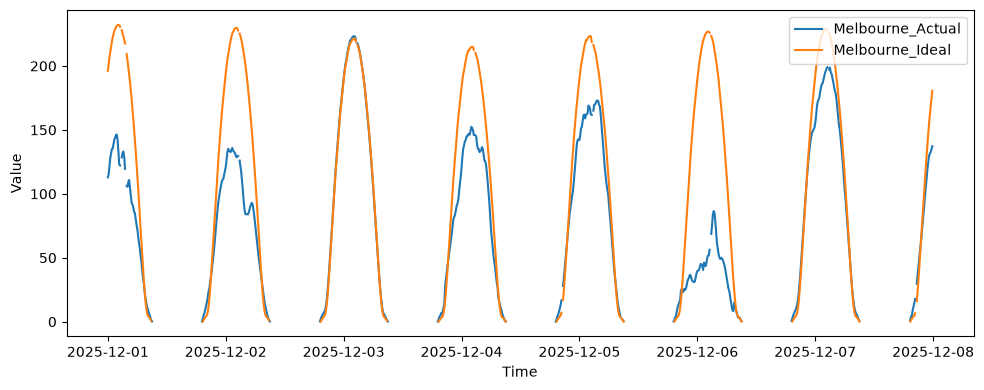

In [6]:
plt.figure(figsize=(10,4))
plt.plot(mel_act.time, mel_act, label="Melbourne_Actual")
plt.plot(mel_ide.time, mel_ide, label="Melbourne_Ideal")

plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

:::{note} `plt.plot(x_variable, y_variable , other things)`
Plots two variables, `x` and `y`, as a time series. Other things you can specify include; `label = “the label for the line”`, `colour = “colour”`, `marker = “*”` or `“- -”` (you can change the line style)
:::

### Scatterplot + regression line + R²

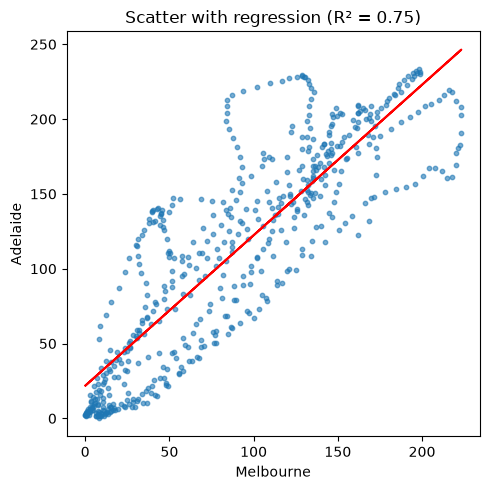

In [7]:
# Raw values
x = mel25.values #.values gives the raw numeric values, removing dimensions time
y = ade25.values

# Remove NaNs / infs <- this was included in the code because the dataset contains NaN values, and the polyfit calculations won't work with NaNs
mask = np.isfinite(x) & np.isfinite(y)
x_clean = x[mask]
y_clean = y[mask]

# Fit line
coef = np.polyfit(x_clean, y_clean, 1)
poly = np.poly1d(coef)

# R²
r2 = np.corrcoef(x_clean, y_clean)[0, 1]**2

plt.figure(figsize=(5,5))
plt.scatter(x_clean, y_clean, s=10, alpha=0.6)
plt.plot(x_clean, poly(x_clean), color="red")

plt.xlabel("Melbourne")
plt.ylabel("Adelaide")
plt.title(f"Scatter with regression (R² = {r2:.2f})")

plt.tight_layout()
plt.show()


::: {note} `plt.scatter(x_variable, y_variable , other things)`
Plots two variables, `x` and `y`, as a scatterplot. Other things you can specify include; `label = “the label for the line”`, `colour = “colour”`, `marker = “*”` or `“- -”` (you can change the line style, `alpha = 0.6` (transparency of the dots), `s = 1` (size of the markers)).
:::

## Comparative Box Plot

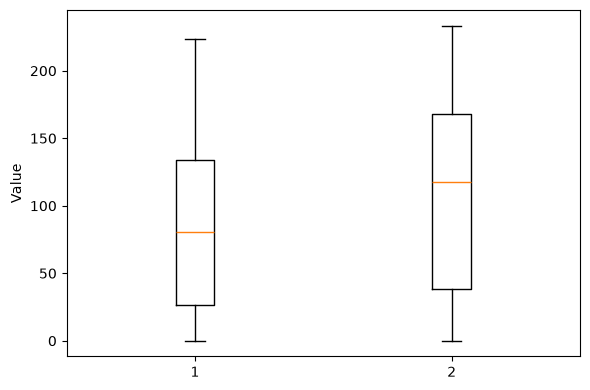

In [9]:
x = mel25.values
y = ade25.values

# Clean NaNs <- this was included in the code because the dataset contains NaN values, and the box plot calculaitons won't work with them
x = x[np.isfinite(x)]
y = y[np.isfinite(y)]

plt.figure(figsize=(6,4))
plt.boxplot([x, y], label=["Melbourne", "Adelaide"])
plt.ylabel("Value")
plt.tight_layout()
plt.show()


::: {note} `plt.boxplot([x, y], labels=["x_label", "y_label"])`
Plots two box plots side by side
:::

## Histograms

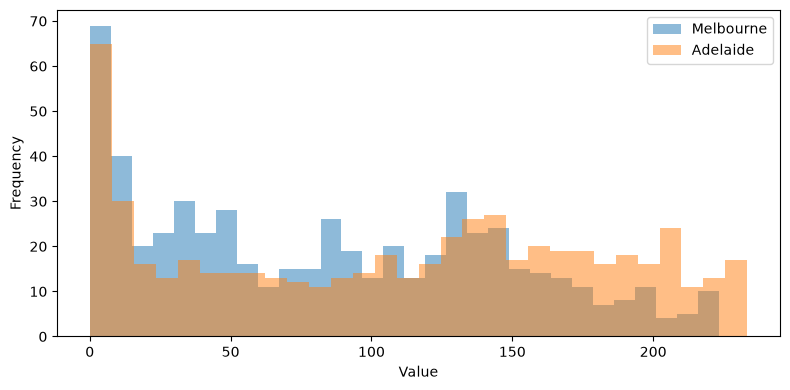

In [10]:
plt.figure(figsize=(8,4))
plt.hist(mel25.values, bins=30, alpha=0.5, label="Melbourne")
plt.hist(ade25.values, bins=30, alpha=0.5, label="Adelaide")

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


::: {note} `plt.hist(da.values, bins=30, alpha=0.5, label="Melbourne")`
Plots a histogram of the numerical values from a data array, `bins = 30` (specifies how many bins to put in your histogram). 
::: 

And side by side histograms.

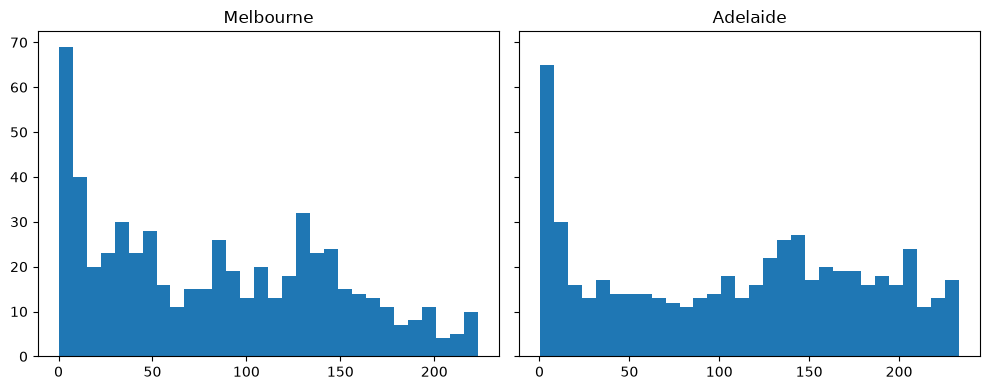

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)

axes[0].hist(mel25.values, bins=30)
axes[0].set_title("Melbourne")

axes[1].hist(ade25.values, bins=30)
axes[1].set_title("Adelaide")

plt.tight_layout()
plt.show()
